# CSC 240 Final Project Prospectus Analysis
arXiv Papers Before and After the Release of ChatGPT

Team: Cheese Cakies

Members: Anela Takiguchi, Lynne Pan, Rhea Guo, Gloria Gan

In [1]:
import json
from email.utils import parsedate_to_datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_PATH = "arxiv-metadata-oai-snapshot.json"   

PRE_START, PRE_END   = pd.Timestamp("2020-01-01"), pd.Timestamp("2022-12-01")  # Jan 2020 – Nov 2022
POST_START, POST_END = pd.Timestamp("2023-07-01"), pd.Timestamp("2025-10-01")  # Jul 2023 – Sep 2025

# ChatGPT's public release date
CHATGPT = pd.Timestamp("2022-11-30")

# Dataset overview
The file has one paper per line. Because it is too large to load at once, we read it line by line and keep only what we need for counting: each paper's ID, main field, the date it was first posted (v1), and the date of its latest version

In [2]:
# arXiv has dozens of physics categories (hep-th, cond-mat, astro-ph, ...)
# we group them all as "physics" so we can compare broad fields
PHYSICS = ("astro-ph", "cond-mat", "gr-qc", "hep-", "math-ph", "nlin", "nucl-", "physics", "quant-ph")

def field_of(categories):

    # a paper can list several categories, e.g. "cs.LG stat.ML"; the first one is its main one
    primary = categories.split()[0]
    archive = primary.split(".")[0] # keep only the part before the dot: "cs.LG" -> "cs"
    if archive.startswith(PHYSICS):
        return "physics"
    return archive  # otherwise: cs, math, stat, eess, econ, q-bio, or q-fin

def to_date(s):
    return parsedate_to_datetime(s).replace(tzinfo=None)

meta = []        # 1 row of basic info per paper
columns = None   # dataset's column names, taken from the 1st paper
n_rows = 0       # numbers of papers read so far


with open(DATA_PATH) as f:
    for line in f:
        p = json.loads(line)
        n_rows += 1
        if columns is None:
            columns = list(p.keys())
        
        # "versions" is the paper's edit history:
        # 1st entry is when it was first posted (v1), the last is its latest update
        v1 = to_date(p["versions"][0]["created"])
        vlast = to_date(p["versions"][-1]["created"])
        fld = field_of(p["categories"])

        # save: ID, field, first-posted date, last-updated date, # of versions
        meta.append((p["id"], fld, v1, vlast, len(p["versions"])))
    
# summary
meta = pd.DataFrame(meta, columns=["id", "field", "v1", "vlast", "n_versions"])
print(f"Rows (papers): {n_rows:,}")
print(f"Columns ({len(columns)}): {columns}")
print(f"v1 date range: {meta.v1.min().date()} to {meta.v1.max().date()}")

Rows (papers): 3,233,620
Columns (14): ['id', 'submitter', 'authors', 'title', 'comments', 'journal-ref', 'doi', 'report-no', 'categories', 'license', 'abstract', 'versions', 'update_date', 'authors_parsed']
v1 date range: 1986-04-25 to 2026-10-29


# Papers by field and period (dated by v1)

In [3]:
# label each paper by when it was first posted:
# "pre" = before-ChatGPT window, "post" = after-ChatGPT window, None = outside both
def period_of(d):
    if PRE_START <= d < PRE_END: return "pre"
    if POST_START <= d < POST_END: return "post"
    return None

meta["period"] = meta.v1.map(period_of)
win = meta.dropna(subset=["period"])

#count papers per field and period
counts = (win.groupby(["field", "period"]).size().unstack()[["pre", "post"]]
          .sort_values("post", ascending=False))

# the windows have different lengths (35 months before, 27 after),
# so compare papers PER MONTH: how much faster are papers coming in after ChatGPT?
PRE_MONTHS, POST_MONTHS = 35, 27
counts["growth_%"] = (100 * ((counts.post / POST_MONTHS) / (counts.pre / PRE_MONTHS) - 1)).round(1)

# total row across all fields (also per month)
total_pre, total_post = counts.pre.sum(), counts.post.sum()
counts.loc["TOTAL"] = [total_pre, total_post,
                       round(100 * ((total_post / POST_MONTHS) / (total_pre / PRE_MONTHS) - 1), 1)]

# show counts as whole numbers 
counts.astype({"pre": int, "post": int})

period,pre,post,growth_%
field,,,
cs,174916,242170,79.5
physics,201286,177832,14.5
math,101495,89307,14.1
eess,25663,25820,30.4
stat,14614,13357,18.5
q-bio,6646,6256,22.0
econ,3627,4117,47.1
q-fin,2571,2419,22.0
TOTAL,530818,561278,37.1


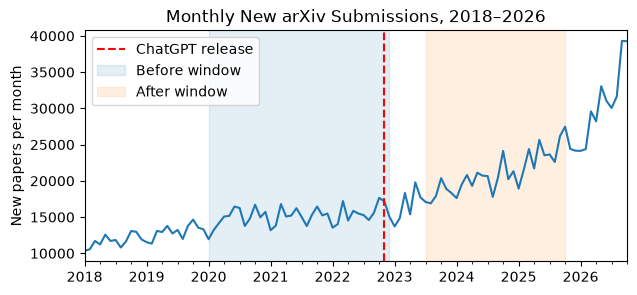

In [4]:
# count new papers per month (by first-posted date), starting from 2018
monthly = meta[meta.v1 >= "2018-01-01"].set_index("v1").resample("MS").size()

fig, ax = plt.subplots(figsize=(7, 3)) 
monthly.plot(ax=ax) # the line: papers per month

# red dashed line on the day ChatGPT was released
ax.axvline(CHATGPT, color="red", ls="--", label="ChatGPT release")

# shade the two time windows
ax.axvspan(PRE_START, PRE_END, color="tab:blue", alpha=0.12, label="Before window")
ax.axvspan(POST_START, POST_END, color="tab:orange", alpha=0.12, label="After window")

ax.set_title("Monthly New arXiv Submissions, 2018–2026")
ax.set_ylabel("New papers per month"); ax.set_xlabel("")
ax.legend()
plt.savefig("fig_monthly_submissions.png", dpi=200)

## version check
The Kaggle snapshot stores the **latest** abstract. A pre-period paper revised after Nov 2022 may carry a post-ChatGPT abstract, so we flag and exclude those from the pre group

In [5]:
# all papers first posted in the "before ChatGPT" window
pre = win[win.period == "pre"]

# True/False for each paper: was its latest version posted after ChatGPT's release?
# If yes, the abstract we have might have been rewritten with ChatGPT's help
revised_after = (pre.vlast >= CHATGPT)

# Overall numbers
# (Averaging True/False values gives the fraction that are True, e.g. 0.115 -> 11.5%)
print(f"Pre-period papers: {len(pre):,}")
print(f"  revised after ChatGPT release: {revised_after.sum():,} ({100*revised_after.mean():.1f}%)")

# same % for each field, smallest to largest
(pre.assign(revised_after=revised_after)
    .groupby("field").revised_after.mean()
    .mul(100).round(1).sort_values()
    .rename("% revised after ChatGPT"))

Pre-period papers: 530,818
  revised after ChatGPT release: 60,906 (11.5%)


field
q-bio       7.4
eess        7.8
physics     9.0
cs          9.9
q-fin      13.5
stat       17.9
math       18.8
econ       23.8
Name: % revised after ChatGPT, dtype: float64